# Day 4 — Retail Cleaning + EDA Challenge

**Dataset:** 7 CSV files from a synthetic Philippine retail / e-commerce store (`customers`, `products`, `orders`, `order_items`, `payments`, `shipments`, `returns`).

**Workflow in this notebook**
1. Setup and load
2. Profile every file (shape, dtypes, missing values, duplicates, key category counts)
3. Clean each file (duplicates, currency, gender/category, mixed dates) and **flag** bad records (invalid age, zero quantity, inconsistent refunds, orphan IDs)
4. Build the item-level analysis table (product category + sales channel)
5. EDA: 7 questions, each with a plain-language finding
6. Cleaning decisions log (what changed, why, how verified)
7. Export cleaned outputs

**Principle used throughout:** *remove only what is verifiably a duplicate; flag everything else instead of silently deleting or "fixing" it.* Every cleaning step is followed by a check (`assert` or a before/after count) so the result is verified, not assumed.

## 1. Setup and load

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = "."                 # folder where the 7 CSV files are
OUT_DIR  = "cleaned_outputs"   # cleaned files will be saved here
os.makedirs(OUT_DIR, exist_ok=True)

NAMES = ["customers", "products", "orders", "order_items", "payments", "shipments", "returns"]

# raw_infer -> pandas guesses the dtypes (useful for PROFILING: shows which columns came in as text by mistake)
raw_infer = {n: pd.read_csv(f"{DATA_DIR}/{n}.csv") for n in NAMES}

# raw -> everything read as text (used for CLEANING so nothing is silently converted,
# e.g. phone numbers keep their leading 0 and "₱1,234.56" is still visible)
raw = {n: pd.read_csv(f"{DATA_DIR}/{n}.csv", dtype=str) for n in NAMES}

{n: df.shape for n, df in raw.items()}

{'customers': (5050, 13),
 'products': (800, 9),
 'orders': (15075, 8),
 'order_items': (37763, 5),
 'payments': (15000, 6),
 'shipments': (15000, 7),
 'returns': (1200, 6)}

## 2. Profile every file

For each file: shape, dtypes, missing values, exact duplicate rows, duplicate keys, and counts of the key category columns.

In [2]:
KEYS = {"customers": "customer_id", "products": "product_id", "orders": "order_id",
        "order_items": "order_item_id", "payments": "payment_id",
        "shipments": "shipment_id", "returns": "return_id"}

CAT_COLS = {"customers": ["gender", "loyalty_tier", "region_name"],
            "products": ["category", "uom"],
            "orders": ["order_status", "sales_channel", "shipping_method"],
            "order_items": ["quantity"],
            "payments": ["payment_method", "payment_status"],
            "shipments": ["courier", "shipment_status"],
            "returns": ["reason", "refunded_flag"]}

def profile(name):
    df = raw_infer[name]
    print("=" * 80)
    print(f"{name.upper()}   shape = {df.shape}")
    print("=" * 80)
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "n_unique": df.nunique()})
    display(info)
    key = KEYS[name]
    print(f"Exact duplicate rows : {df.duplicated().sum():,}")
    print(f"Duplicate {key:<14}: {df[key].duplicated().sum():,}")
    for col in CAT_COLS[name]:
        print(f"\n-- value counts: {col} --")
        print(df[col].value_counts(dropna=False).sort_index().to_string())

summary = pd.DataFrame({
    n: {"rows": len(d), "columns": d.shape[1],
        "total_missing_cells": int(d.isna().sum().sum()),
        "exact_duplicate_rows": int(d.duplicated().sum()),
        "duplicate_key_rows": int(d[KEYS[n]].duplicated().sum())}
    for n, d in raw_infer.items()}).T
summary

,rows,columns,total_missing_cells,exact_duplicate_rows,duplicate_key_rows
customers,5050,13,971,50,50
products,800,9,19,0,0
orders,15075,8,1232,75,75
order_items,37763,5,2262,262,262
payments,15000,6,878,0,0
shipments,15000,7,729,0,0
returns,1200,6,297,0,0


In [3]:
profile("customers")

CUSTOMERS   shape = (5050, 13)


,dtype,missing,missing_%,n_unique
customer_id,str,0,0.00,5000
first_name,str,0,0.00,20
last_name,str,0,0.00,20
gender,str,301,5.96,6
age,float64,150,2.97,66
email,str,107,2.12,3360
phone,float64,147,2.91,4855
region_code,str,0,0.00,6
region_name,str,0,0.00,6
city,str,0,0.00,24


Exact duplicate rows : 50
Duplicate customer_id   : 50

-- value counts: gender --
gender
F          1275
Female      731
M          1310
Male        725
Unknown     593
female      115
NaN         301

-- value counts: loyalty_tier --
loyalty_tier
Bronze      2227
Gold         923
Platinum     362
Silver      1272
NaN          266

-- value counts: region_name --
region_name
CALABARZON           846
Caraga               822
Central Luzon        864
Central Visayas      849
Metro Manila         854
Northern Mindanao    815


In [4]:
profile("products")

PRODUCTS   shape = (800, 9)


,dtype,missing,missing_%,n_unique
product_id,str,0,0.00,800
product_name,str,0,0.00,797
brand,str,0,0.00,10
category,str,0,0.00,18
unit_cost,float64,0,0.00,768
unit_price,str,0,0.00,781
stock_qty,float64,19,2.38,230
uom,str,0,0.00,6
launch_date,str,0,0.00,601


Exact duplicate rows : 0
Duplicate product_id    : 0

-- value counts: category --
category
Beauty              94
Beauty & Care       11
Book                20
Books               90
Elec                11
Electronics         71
Electronics         17
Fashion             89
Fashon               8
Groceries           77
Grocery             12
Home & Kitchen      76
Home and Kitchen    19
Sports              74
Sports & Outdoor     8
Toy                 11
Toys                92
electronics         20

-- value counts: uom --
uom
bottle    123
pack      125
pc        133
pcs       156
piece     140
set       123


In [5]:
profile("orders")

ORDERS   shape = (15075, 8)


,dtype,missing,missing_%,n_unique
order_id,str,0,0.00,15000
customer_id,str,0,0.00,4755
order_datetime,str,0,0.00,14934
order_status,str,0,0.00,5
sales_channel,str,0,0.00,3
shipping_method,str,0,0.00,3
discount_pct,float64,758,5.03,317
shipping_fee,float64,474,3.14,8702


Exact duplicate rows : 75
Duplicate order_id      : 75

-- value counts: order_status --
order_status
Cancelled    1238
Completed    9903
Pending      1538
Returned      582
Shipped      1814

-- value counts: sales_channel --
sales_channel
Marketplace    5070
Mobile App     5007
Web            4998

-- value counts: shipping_method --
shipping_method
Express     5062
Pickup      4943
Standard    5070


In [6]:
profile("order_items")

ORDER_ITEMS   shape = (37763, 5)


,dtype,missing,missing_%,n_unique
order_item_id,str,0,0.00,37501
order_id,str,0,0.00,15000
product_id,str,0,0.00,801
quantity,int64,0,0.00,11
unit_price_at_purchase,str,2262,5.99,781


Exact duplicate rows : 262
Duplicate order_item_id : 262

-- value counts: quantity --
quantity
0       378
1     15218
2     10073
3      6748
4      3373
5      1345
6       452
7       133
8        32
9        10
10        1


In [7]:
profile("payments")

PAYMENTS   shape = (15000, 6)


,dtype,missing,missing_%,n_unique
payment_id,str,0,0.00,15000
order_id,str,0,0.00,15000
payment_method,str,0,0.00,5
payment_status,str,0,0.00,4
payment_date,str,0,0.00,1487
amount_paid,str,878,5.85,13182


Exact duplicate rows : 0
Duplicate payment_id    : 0

-- value counts: payment_method --
payment_method
Bank Transfer    2873
COD              3030
Credit Card      3137
GCash            2925
PayMaya          3035

-- value counts: payment_status --
payment_status
Failed        614
Paid        12448
Pending      1492
Refunded      446


In [8]:
profile("shipments")

SHIPMENTS   shape = (15000, 7)


,dtype,missing,missing_%,n_unique
shipment_id,str,0,0.00,15000
order_id,str,0,0.00,15000
courier,str,0,0.00,5
tracking_no,str,0,0.00,15000
shipment_status,str,0,0.00,4
ship_date,str,0,0.00,1482
delivered_date,str,729,4.86,1494


Exact duplicate rows : 0


Duplicate shipment_id   : 0

-- value counts: courier --
courier
2GO            2951
GrabExpress    3011
J&T            3042
LBC            3011
NinjaVan       2985

-- value counts: shipment_status --
shipment_status
Delivered             11680
In Transit             2694
Lost                    161
Returned to Sender      465


In [9]:
profile("returns")

RETURNS   shape = (1200, 6)


,dtype,missing,missing_%,n_unique
return_id,str,0,0.00,1200
order_id,str,0,0.00,1200
return_request_date,str,0,0.00,739
reason,str,0,0.00,7
refunded_flag,str,110,9.17,3
refund_amount,float64,187,15.58,942


Exact duplicate rows : 0
Duplicate return_id     : 0

-- value counts: reason --
reason
Changed mind     182
Damaged item     160
Defective        178
Late delivery    169
Missing parts    175
Size issue       174
Wrong item       162

-- value counts: refunded_flag --
refunded_flag
No         301
Partial    136
Yes        653
NaN        110


### Profiling observations (what the profile tells us)

| File | What I noticed | Action |
|---|---|---|
| customers | 50 exact duplicate rows; `gender` has `M/F/Male/Female/female/Unknown/blank`; `age` has negative values; some emails have no `@`; phone is shorter than 11 digits in some rows; `signup_date` is `object` (mixed formats) | dedupe, normalize, flag, parse |
| products | `category` has typos and variants (`Fashon`, `Elec`, `Grocery`...); `unit_price` is `object` because some values are `₱1,234.56` | standardize, strip currency |
| orders | 75 exact duplicate rows; `order_datetime` mixed formats; nulls in `discount_pct` and `shipping_fee` | dedupe, parse, flag nulls |
| order_items | 262 exact duplicate rows; `quantity = 0`; `unit_price_at_purchase` is `object` (₱ strings) and has nulls; some `product_id` do not exist | dedupe, flag, strip currency, backfill price |
| payments | `amount_paid` is `object` (₱ strings) with nulls; `payment_date` mixed | strip currency, parse, compare to computed totals |
| shipments | mixed dates; `delivered_date` has nulls | parse, flag conflicts |
| returns | `refunded_flag` has blanks; `refund_amount` has nulls | flag inconsistent refund records |

## 3. Cleaning

### 3.0 Helper functions
Three helpers are reused everywhere so each file is cleaned the same way.

In [10]:
def parse_mixed_dates(s, formats):
    """Try each known format in turn. Values that match none stay NaT (never guessed)."""
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for f in formats:
        out = out.fillna(pd.to_datetime(s, format=f, errors="coerce"))
    return out

def to_money(s):
    """'₱1,234.56' -> 1234.56 ; plain numbers pass through ; blanks stay NaN."""
    return pd.to_numeric(s.astype("string").str.replace(r"[₱,\s]", "", regex=True), errors="coerce")

DATE_FORMATS     = ["%Y-%m-%d", "%m/%d/%Y", "%d-%b-%Y"]                              # README: YYYY-MM-DD, MM/DD/YYYY, dd-Mon-YYYY
DATETIME_FORMATS = ["%Y-%m-%d %H:%M:%S", "%m/%d/%Y %I:%M %p", "%d-%b-%Y %H:%M"]

def check_dates(before, after, label):
    """Verification: the parser must not lose or invent any date."""
    assert before.notna().sum() == after.notna().sum(), f"{label}: parsing lost/created dates"
    print(f"[OK] {label}: {after.notna().sum():,} dates parsed, 0 unparseable, "
          f"range {after.min():%Y-%m-%d} to {after.max():%Y-%m-%d}")

log_counts = {}   # filled while cleaning, used later in the decisions log

### 3.1 customers
- Remove **exact** duplicate rows only (then confirm `customer_id` is unique).
- `gender` → `Male / Female / Unknown` (blank and "Unknown" both become `Unknown`).
- `age` < 0 is impossible → set to `NaN` and keep a flag `age_invalid`.
- Email and phone are **flagged** (`email_status`, `phone_status`), not guessed.
- `signup_date` → real datetime. `loyalty_tier` blank → `Unknown`.

In [11]:
c = raw["customers"].copy()
n_before = len(c)

# 1) exact duplicates
c = c.drop_duplicates().reset_index(drop=True)
log_counts["cust_dups"] = n_before - len(c)
assert c["customer_id"].is_unique, "customer_id still duplicated -> some duplicates are not exact"
print(f"Removed {log_counts['cust_dups']} exact duplicate rows; customer_id is now unique ({len(c):,} rows)")

# 2) tidy text
for col in ["first_name", "last_name", "city", "barangay", "region_name"]:
    c[col] = c[col].str.strip()

# 3) gender
log_counts["gender_before"] = c["gender"].nunique(dropna=False)
c["gender"] = (c["gender"].str.strip().str.lower()
                 .map({"m": "Male", "male": "Male", "f": "Female", "female": "Female"})
                 .fillna("Unknown"))
assert set(c["gender"].unique()) <= {"Male", "Female", "Unknown"}
print("gender:", c["gender"].value_counts().to_dict())

# 4) age
c["age"] = pd.to_numeric(c["age"])
c["age_invalid"] = c["age"] < 0
log_counts["age_invalid"] = int(c["age_invalid"].sum())
c.loc[c["age_invalid"], "age"] = np.nan
assert (c["age"].dropna() >= 0).all()
print(f"age: {log_counts['age_invalid']} negative ages set to NaN and flagged; {c['age'].isna().sum()} total missing")

# 5) email + phone flags
c["email"] = c["email"].str.strip().str.lower()
valid_email = c["email"].str.match(r"^[\w.+-]+@[\w-]+(\.[\w-]+)+$", na=False)
c["email_status"] = np.where(c["email"].isna(), "missing", np.where(valid_email, "valid", "malformed"))
c["phone"] = c["phone"].str.strip()
valid_phone = c["phone"].str.match(r"^09\d{9}$", na=False)
c["phone_status"] = np.where(c["phone"].isna(), "missing", np.where(valid_phone, "valid", "invalid_format"))
print("email_status:", c["email_status"].value_counts().to_dict())
print("phone_status:", c["phone_status"].value_counts().to_dict())
log_counts["email_malformed"] = int((c["email_status"] == "malformed").sum())

# 6) dates + tier
before = c["signup_date"]
c["signup_date"] = parse_mixed_dates(before, DATE_FORMATS)
check_dates(before, c["signup_date"], "customers.signup_date")
c["loyalty_tier"] = c["loyalty_tier"].fillna("Unknown")

customers_clean = c
customers_clean.head()

Removed 50 exact duplicate rows; customer_id is now unique (5,000 rows)
gender: {'Female': 2099, 'Male': 2016, 'Unknown': 885}
age: 48 negative ages set to NaN and flagged; 197 total missing


email_status: {'valid': 4671, 'malformed': 225, 'missing': 104}
phone_status: {'valid': 4722, 'missing': 145, 'invalid_format': 133}


[OK] customers.signup_date: 5,000 dates parsed, 0 unparseable, range 2023-01-01 to 2026-01-31


,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier,age_invalid,email_status,phone_status
0,CUST000001,Grace,DelosReyes,Unknown,20.00,grace.delosreyes95@outlook.com,09196001338,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze,False,valid,valid
1,CUST000002,Ana,Ramos,Female,35.00,ana.ramos@companymail.ph,09026542351,CARAGA,Caraga,Butuan,Brgy 9,2025-02-08,Bronze,False,valid,valid
2,CUST000003,Arvin,Navarro,Male,14.00,arvin.navarrooutlook.com,09161849593,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze,False,malformed,valid
3,CUST000004,Kyle,Rivera,Female,26.00,kyle.rivera13@outlook.com,09752553419,Region III,Central Luzon,Angeles,Brgy 1,2024-11-17,Unknown,False,valid,valid
4,CUST000005,Juan,Mendoza,Male,29.00,juan.mendoza@gmail.com,09350305641,Region III,Central Luzon,Angeles,Brgy 9,2023-01-21,Gold,False,valid,valid


### 3.2 products
- `category`: lower-case + trim, then map every variant to one of 8 standard names. The `assert` makes the code **fail loudly** if a variant is not in the map.
- `unit_cost`, `unit_price`: remove `₱` and commas → numeric.
- `uom` (pcs / piece / pc) → `pc`. Missing `stock_qty` is kept as `NaN` and flagged.

In [12]:
p = raw["products"].copy()
assert p["product_id"].is_unique

CATEGORY_MAP = {
    "beauty": "Beauty", "beauty & care": "Beauty",
    "toys": "Toys", "toy": "Toys",
    "books": "Books", "book": "Books",
    "fashion": "Fashion", "fashon": "Fashion",
    "groceries": "Groceries", "grocery": "Groceries",
    "home & kitchen": "Home & Kitchen", "home and kitchen": "Home & Kitchen",
    "electronics": "Electronics", "elec": "Electronics",
    "sports": "Sports", "sports & outdoor": "Sports",
}
log_counts["cat_before"] = p["category"].nunique()
cat_key = p["category"].str.strip().str.lower()
assert cat_key.isin(CATEGORY_MAP).all(), f"Unmapped: {set(cat_key[~cat_key.isin(CATEGORY_MAP)])}"
p["category"] = cat_key.map(CATEGORY_MAP)
log_counts["cat_after"] = p["category"].nunique()
print(f"category: {log_counts['cat_before']} labels -> {log_counts['cat_after']} labels")
print(p["category"].value_counts().to_string())

# currency
raw_price, raw_cost = p["unit_price"].copy(), p["unit_cost"].copy()
p["unit_price"], p["unit_cost"] = to_money(raw_price), to_money(raw_cost)
log_counts["prod_currency_fixed"] = int(raw_price.str.contains("[₱,]", na=False).sum() + raw_cost.str.contains("[₱,]", na=False).sum())
assert p["unit_price"].notna().sum() == raw_price.notna().sum(), "price parsing created NaN"
assert p["unit_cost"].notna().sum() == raw_cost.notna().sum(), "cost parsing created NaN"
print(f"currency: {log_counts['prod_currency_fixed']} price/cost cells contained ₱ or commas -> now numeric")

# sanity checks
p["price_below_cost"] = p["unit_price"] < p["unit_cost"]
print("non-positive prices:", int((p["unit_price"] <= 0).sum()), "| price below cost:", int(p["price_below_cost"].sum()))

p["uom"] = p["uom"].str.strip().str.lower().replace({"pcs": "pc", "piece": "pc"})
p["stock_qty"] = pd.to_numeric(p["stock_qty"])
p["stock_missing"] = p["stock_qty"].isna()
before = p["launch_date"]; p["launch_date"] = parse_mixed_dates(before, DATE_FORMATS)
check_dates(before, p["launch_date"], "products.launch_date")

products_clean = p
products_clean.head()

category: 18 labels -> 8 labels
category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82


currency: 68 price/cost cells contained ₱ or commas -> now numeric
non-positive prices: 0 | price below cost: 0
[OK] products.launch_date: 800 dates parsed, 0 unparseable, range 2022-01-03 to 2024-09-26


,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date,price_below_cost,stock_missing
0,PROD00001,KidJoy Beauty 963,KidJoy,Beauty,44.17,64.50,125.00,pc,2022-01-18,False,False
1,PROD00002,HomeEase Home 368,HomeEase,Home & Kitchen,37.18,70.39,131.00,pc,2022-11-25,False,False
2,PROD00003,FreshCart Fashion 911,FreshCart,Fashion,46.29,70.26,41.00,pc,2023-09-04,False,False
3,PROD00004,NovaTech Toys 753,NovaTech,Toys,43.66,62.46,149.00,pc,2023-08-12,False,False
4,PROD00005,GlowCo Books 916,GlowCo,Books,64.59,82.02,162.00,bottle,2024-05-12,False,False


### 3.3 orders
- `order_id` is meant to be the primary key but has intentional duplicates → remove **exact** duplicate rows and verify uniqueness.
- `order_datetime` → real datetime (3 formats).
- `discount_pct` / `shipping_fee` nulls: keep the original column, add `*_missing` flags, and create `*_filled` columns (`0` assumed) used only for revenue maths.
- Flag `orphan_customer` (customer_id not in customers).

In [13]:
o = raw["orders"].copy()
n_before = len(o)
o = o.drop_duplicates().reset_index(drop=True)
log_counts["orders_dups"] = n_before - len(o)
assert o["order_id"].is_unique, "order_id still duplicated -> some duplicates are not exact"
print(f"Removed {log_counts['orders_dups']} exact duplicate rows; order_id unique ({len(o):,} orders)")

before = o["order_datetime"]
o["order_datetime"] = parse_mixed_dates(before, DATETIME_FORMATS)
check_dates(before, o["order_datetime"], "orders.order_datetime")

for col in ["order_status", "sales_channel", "shipping_method"]:
    o[col] = o[col].str.strip()

o["discount_pct"] = pd.to_numeric(o["discount_pct"])
o["shipping_fee"] = pd.to_numeric(o["shipping_fee"])
assert o["discount_pct"].dropna().between(0, 1).all(), "discount outside 0-1"
assert (o["shipping_fee"].dropna() >= 0).all(), "negative shipping fee"
o["discount_missing"] = o["discount_pct"].isna()
o["shipping_fee_missing"] = o["shipping_fee"].isna()
o["discount_pct_filled"] = o["discount_pct"].fillna(0)
o["shipping_fee_filled"] = o["shipping_fee"].fillna(0)
log_counts["disc_missing"] = int(o["discount_missing"].sum())
log_counts["ship_missing"] = int(o["shipping_fee_missing"].sum())

o["orphan_customer"] = ~o["customer_id"].isin(customers_clean["customer_id"])
log_counts["orphan_customer_orders"] = int(o["orphan_customer"].sum())
print("orphan customer orders:", log_counts["orphan_customer_orders"], "->", o.loc[o["orphan_customer"], "customer_id"].unique().tolist())

orders_clean = o
orders_clean.head()

Removed 75 exact duplicate rows; order_id unique (15,000 orders)


[OK] orders.order_datetime: 15,000 dates parsed, 0 unparseable, range 2024-01-01 to 2026-01-31


orphan customer orders: 43 -> ['CUST999999']


,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee,discount_missing,shipping_fee_missing,discount_pct_filled,shipping_fee_filled,orphan_customer
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.07,102.68,False,False,0.07,102.68,False
1,ORD0000002,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,0.00,False,False,0.06,0.00,False
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.14,103.83,False,False,0.14,103.83,False
3,ORD0000004,CUST002515,2025-10-14 12:56:00,Completed,Web,Pickup,0.01,112.69,False,False,0.01,112.69,False
4,ORD0000005,CUST001544,2024-05-30 04:56:00,Completed,Marketplace,Pickup,NaN,111.73,True,False,0.00,111.73,False


### 3.4 order_items
- Remove exact duplicate rows; confirm `order_item_id` is unique.
- `quantity = 0` is invalid → **flag** `zero_qty` (kept in the file, excluded from revenue).
- `unit_price_at_purchase`: strip `₱`/commas; null prices are **backfilled from `products.unit_price`** (the README allows this) and the source is recorded in `price_source`.
- Flag `orphan_product` (product_id not in products).

In [14]:
oi = raw["order_items"].copy()
n_before = len(oi)
oi = oi.drop_duplicates().reset_index(drop=True)
log_counts["items_dups"] = n_before - len(oi)
assert oi["order_item_id"].is_unique
print(f"Removed {log_counts['items_dups']} exact duplicate rows; order_item_id unique ({len(oi):,} rows)")

oi["quantity"] = pd.to_numeric(oi["quantity"]).astype(int)
oi["zero_qty"] = oi["quantity"] == 0
log_counts["zero_qty"] = int(oi["zero_qty"].sum())

raw_p = oi["unit_price_at_purchase"].copy()
oi["unit_price_at_purchase"] = to_money(raw_p)
assert oi["unit_price_at_purchase"].notna().sum() == raw_p.notna().sum(), "price parsing created NaN"
log_counts["item_currency_fixed"] = int(raw_p.str.contains("[₱,]", na=False).sum())

# orphans
oi["orphan_product"] = ~oi["product_id"].isin(products_clean["product_id"])
oi["orphan_order"]   = ~oi["order_id"].isin(orders_clean["order_id"])
log_counts["orphan_product"] = int(oi["orphan_product"].sum())
print("orphan product rows:", log_counts["orphan_product"], "->", oi.loc[oi["orphan_product"], "product_id"].unique().tolist())
print("orphan order rows  :", int(oi["orphan_order"].sum()))

# backfill missing price from the product master
catalog_price = oi["product_id"].map(products_clean.set_index("product_id")["unit_price"])
oi["price_source"] = np.where(oi["unit_price_at_purchase"].notna(), "recorded",
                       np.where(catalog_price.notna(), "backfilled_from_products", "unavailable"))
oi["unit_price_at_purchase"] = oi["unit_price_at_purchase"].fillna(catalog_price)
log_counts["price_backfilled"] = int((oi["price_source"] == "backfilled_from_products").sum())
log_counts["price_unavailable"] = int((oi["price_source"] == "unavailable").sum())
print(oi["price_source"].value_counts().to_string())

order_items_clean = oi
order_items_clean.head()

Removed 262 exact duplicate rows; order_item_id unique (37,501 rows)


orphan product rows: 129 -> ['PROD00000']
orphan order rows  : 0


price_source
recorded                    35265
backfilled_from_products     2227
unavailable                     9


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,zero_qty,orphan_product,orphan_order,price_source
0,ITEM000000001,ORD0000001,PROD00513,2,120.67,False,False,False,recorded
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,False,False,False,recorded
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,False,False,False,recorded
3,ITEM000000004,ORD0000002,PROD00136,1,100.59,False,False,False,recorded
4,ITEM000000005,ORD0000002,PROD00090,1,109.18,False,False,False,recorded


### 3.5 payments
- Strip `₱`/commas from `amount_paid`; parse `payment_date`.
- Missing amounts are kept as `NaN` (not invented). The comparison against computed order totals is done in section 4.

In [15]:
pay = raw["payments"].copy()
assert pay["payment_id"].is_unique
raw_a = pay["amount_paid"].copy()
pay["amount_paid"] = to_money(raw_a)
assert pay["amount_paid"].notna().sum() == raw_a.notna().sum()
log_counts["pay_currency_fixed"] = int(raw_a.str.contains("[₱,]", na=False).sum())
log_counts["pay_missing"] = int(pay["amount_paid"].isna().sum())
before = pay["payment_date"]; pay["payment_date"] = parse_mixed_dates(before, DATE_FORMATS)
check_dates(before, pay["payment_date"], "payments.payment_date")
pay["amount_missing"] = pay["amount_paid"].isna()
print("payments with order_id not in orders:", int((~pay["order_id"].isin(orders_clean["order_id"])).sum()))
print("orders with more than one payment   :", int(pay["order_id"].duplicated().sum()))
payments_clean = pay
payments_clean.head()

[OK] payments.payment_date: 15,000 dates parsed, 0 unparseable, range 2024-01-01 to 2026-01-31
payments with order_id not in orders: 0
orders with more than one payment   : 0


,payment_id,order_id,payment_method,payment_status,payment_date,amount_paid,amount_missing
0,PAY0000001,ORD0000001,GCash,Paid,2024-05-09,"2,822.72",False
1,PAY0000002,ORD0000002,COD,Paid,2024-06-25,"2,499.76",False
2,PAY0000003,ORD0000003,GCash,Paid,2025-06-10,"1,983.66",False
3,PAY0000004,ORD0000004,PayMaya,Failed,2025-06-21,"1,765.99",False
4,PAY0000005,ORD0000005,COD,Pending,2024-06-28,"1,477.53",False


### 3.6 shipments
- Parse `ship_date` and `delivered_date`.
- Add `lead_days` (delivered − shipped) and flags for records that contradict each other:
  - `delivered_before_shipped`
  - `status_date_conflict` — e.g. status is *In Transit* but a delivered date exists, or status is *Delivered* but the date is empty.

In [16]:
s = raw["shipments"].copy()
assert s["shipment_id"].is_unique
for col in ["ship_date", "delivered_date"]:
    before = s[col]; s[col] = parse_mixed_dates(before, DATE_FORMATS)
    check_dates(before, s[col], f"shipments.{col}")

s["lead_days"] = (s["delivered_date"] - s["ship_date"]).dt.days
s["delivered_before_shipped"] = s["lead_days"] < 0
s["status_date_conflict"] = (
    ((s["shipment_status"] == "Delivered") & s["delivered_date"].isna()) |
    ((s["shipment_status"] != "Delivered") & s["delivered_date"].notna())
)
print("delivered_before_shipped:", int(s["delivered_before_shipped"].sum()))
print("status_date_conflict    :", int(s["status_date_conflict"].sum()))
print(pd.crosstab(s["shipment_status"], s["delivered_date"].notna().rename("has_delivered_date")))
print(s["lead_days"].describe().round(2).to_string())
log_counts["ship_conflict"] = int(s["status_date_conflict"].sum())
shipments_clean = s
shipments_clean.head()

[OK] shipments.ship_date: 15,000 dates parsed, 0 unparseable, range 2024-01-01 to 2026-01-31


[OK] shipments.delivered_date: 14,271 dates parsed, 0 unparseable, range 2024-01-02 to 2026-02-07
delivered_before_shipped: 0
status_date_conflict    : 3707
has_delivered_date  False  True 
shipment_status                 
Delivered             558  11122
In Transit            137   2557
Lost                   10    151
Returned to Sender     24    441
count   14,271.00
mean         4.00
std          1.99
min          1.00
25%          2.00
50%          4.00
75%          6.00
max          7.00


,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date,lead_days,delivered_before_shipped,status_date_conflict
0,SHP0000001,ORD0000001,J&T,HLI2ORMO9V4O,Delivered,2025-09-05,2025-09-06,1.00,False,False
1,SHP0000002,ORD0000002,NinjaVan,E8XLRMV7QVEB,In Transit,2025-02-06,2025-02-12,6.00,False,True
2,SHP0000003,ORD0000003,2GO,LHLXVJF18MQB,Delivered,2025-07-23,2025-07-29,6.00,False,False
3,SHP0000004,ORD0000004,GrabExpress,RXUNTQ7WKL5B,Delivered,2025-01-21,2025-01-25,4.00,False,False
4,SHP0000005,ORD0000005,2GO,XQLUM80WBUSJ,In Transit,2025-09-21,2025-09-26,5.00,False,True


### 3.7 returns — inconsistent refund records
`refunded_flag` and `refund_amount` should agree. A record is flagged `refund_inconsistent` when:

| Case | Why it is a problem |
|---|---|
| flag = **Yes** but amount is empty or 0 | says money was refunded but no amount recorded |
| flag = **Partial** but amount is empty or 0 | a partial refund must have an amount |
| flag = **No** but amount > 0 | says no refund but an amount exists |
| flag is **blank** but amount > 0 | refund exists but status unknown |

In [17]:
r = raw["returns"].copy()
assert r["return_id"].is_unique
r["return_request_date"] = parse_mixed_dates(raw["returns"]["return_request_date"], DATE_FORMATS)
check_dates(raw["returns"]["return_request_date"], r["return_request_date"], "returns.return_request_date")
r["refund_amount"] = pd.to_numeric(r["refund_amount"])
r["refunded_flag"] = r["refunded_flag"].str.strip().str.title()
r["refunded_flag_original"] = r["refunded_flag"]
r["refunded_flag"] = r["refunded_flag"].fillna("Unknown")

amt_empty = r["refund_amount"].isna() | (r["refund_amount"] == 0)
amt_pos   = r["refund_amount"] > 0
r["refund_issue"] = np.select(
    [r["refunded_flag"].isin(["Yes", "Partial"]) & amt_empty,
     (r["refunded_flag"] == "No") & amt_pos,
     (r["refunded_flag"] == "Unknown") & amt_pos],
    ["flag says refunded but amount missing/0",
     "flag says No but amount > 0",
     "flag blank but amount > 0"],
    default="")
r["refund_inconsistent"] = r["refund_issue"] != ""
log_counts["refund_inconsistent"] = int(r["refund_inconsistent"].sum())

# extra consistency check against the order itself: a return should not exist for an order that never shipped
r["order_status"] = r["order_id"].map(orders_clean.set_index("order_id")["order_status"])
r["return_on_unshipped_order"] = r["order_status"].isin(["Cancelled", "Pending"])
log_counts["return_unshipped"] = int(r["return_on_unshipped_order"].sum())
print("returns attached to Cancelled/Pending orders:", log_counts["return_unshipped"])
print("orders with status 'Returned' that have NO return record:",
      int((~orders_clean.loc[orders_clean["order_status"] == "Returned", "order_id"].isin(r["order_id"])).sum()),
      "of", int((orders_clean["order_status"] == "Returned").sum()))
print(r["refund_issue"].replace("", "consistent").value_counts().to_string())
print("returns with order_id not in orders:", int((~r["order_id"].isin(orders_clean["order_id"])).sum()))
returns_clean = r
returns_clean.head()

[OK] returns.return_request_date: 1,200 dates parsed, 0 unparseable, range 2024-01-01 to 2026-01-29
returns attached to Cancelled/Pending orders: 201
orders with status 'Returned' that have NO return record: 538 of 578
refund_issue
consistent                                 719
flag says No but amount > 0                232
flag says refunded but amount missing/0    164
flag blank but amount > 0                   85
returns with order_id not in orders: 0


,return_id,order_id,return_request_date,reason,refunded_flag,refund_amount,refunded_flag_original,refund_issue,refund_inconsistent,order_status,return_on_unshipped_order
0,RET000001,ORD0008752,2025-01-09,Defective,No,NaN,No,,False,Completed,False
1,RET000002,ORD0007359,2025-07-20,Wrong item,Unknown,650.28,NaN,flag blank but amount > 0,True,Completed,False
2,RET000003,ORD0009041,2025-01-07,Size issue,Yes,NaN,Yes,flag says refunded but amount missing/0,True,Completed,False
3,RET000004,ORD0000227,2025-03-04,Late delivery,Partial,NaN,Partial,flag says refunded but amount missing/0,True,Completed,False
4,RET000005,ORD0005754,2025-04-24,Size issue,Yes,713.39,Yes,,False,Cancelled,True


## 4. Item-level analysis table

One row per `order_item`, enriched with product category, brand, order date, **sales channel**, order status, discount, and customer region/tier.

**Revenue definitions (used in all EDA)**
- `gross_amount = quantity × unit_price_at_purchase`
- `net_revenue  = gross_amount × (1 − discount_pct)` (discount is order-level, so it is applied to every line of the order)
- `valid_line` = quantity > 0 **and** product exists **and** a price is available
- `counts_as_revenue` = `valid_line` **and** order status is not *Cancelled*

Orphan products get category `Unknown (orphan product)` so they stay visible instead of disappearing from a join.

In [18]:
items = (order_items_clean
         .merge(orders_clean[["order_id", "customer_id", "order_datetime", "order_status", "sales_channel",
                              "shipping_method", "discount_pct_filled", "orphan_customer"]],
                on="order_id", how="left", validate="many_to_one")
         .merge(products_clean[["product_id", "product_name", "brand", "category", "unit_cost"]],
                on="product_id", how="left", validate="many_to_one")
         .merge(customers_clean[["customer_id", "region_name", "loyalty_tier", "gender"]],
                on="customer_id", how="left", validate="many_to_one"))

assert len(items) == len(order_items_clean), "a join changed the number of rows"   # verification: no row explosion
items["category"] = items["category"].fillna("Unknown (orphan product)")

items["gross_amount"] = items["quantity"] * items["unit_price_at_purchase"]
items["net_revenue"]  = items["gross_amount"] * (1 - items["discount_pct_filled"])
items["cost_amount"]  = items["quantity"] * items["unit_cost"]
items["valid_line"]   = (items["quantity"] > 0) & (~items["orphan_product"]) & items["unit_price_at_purchase"].notna()
items["counts_as_revenue"] = items["valid_line"] & (items["order_status"] != "Cancelled")
items["order_month"]  = items["order_datetime"].dt.to_period("M").astype(str)

print(f"rows: {len(items):,} | valid lines: {items['valid_line'].sum():,} | counted as revenue: {items['counts_as_revenue'].sum():,}")
items[["order_item_id", "order_id", "order_datetime", "sales_channel", "category", "product_name", "quantity",
       "unit_price_at_purchase", "discount_pct_filled", "net_revenue", "order_status", "valid_line", "counts_as_revenue"]].head(8)

rows: 37,501 | valid lines: 37,002 | counted as revenue: 34,015


,order_item_id,order_id,order_datetime,sales_channel,category,product_name,quantity,unit_price_at_purchase,discount_pct_filled,net_revenue,order_status,valid_line,counts_as_revenue
0,ITEM000000001,ORD0000001,2025-11-07 17:02:00,Marketplace,Sports,HomeEase Sports 313,2,120.67,0.07,223.48,Cancelled,True,False
1,ITEM000000002,ORD0000002,2025-09-18 09:13:00,Marketplace,Beauty,NovaTech Beauty 892,2,83.58,0.06,156.63,Completed,True,True
2,ITEM000000003,ORD0000002,2025-09-18 09:13:00,Marketplace,Electronics,BookNest Electronics 252,2,46.96,0.06,88.00,Completed,True,True
3,ITEM000000004,ORD0000002,2025-09-18 09:13:00,Marketplace,Groceries,GlowCo Groceries 689,1,100.59,0.06,94.25,Completed,True,True
4,ITEM000000005,ORD0000002,2025-09-18 09:13:00,Marketplace,Home & Kitchen,BookNest Home 591,1,109.18,0.06,102.30,Completed,True,True
5,ITEM000000006,ORD0000002,2025-09-18 09:13:00,Marketplace,Toys,KidJoy Toys 220,2,54.41,0.06,101.96,Completed,True,True
6,ITEM000000007,ORD0000003,2025-08-08 04:59:00,Web,Electronics,KidJoy Electronics 871,2,85.94,0.14,148.33,Completed,True,True
7,ITEM000000008,ORD0000003,2025-08-08 04:59:00,Web,Books,NovaTech Books 667,1,117.13,0.14,101.08,Completed,True,True


### 4.1 Data-quality flag summary (all required flags in one table)

In [19]:
flag_summary = pd.DataFrame([
    ("customers", "Invalid age (negative)",                          int(customers_clean["age_invalid"].sum())),
    ("customers", "Missing age",                                     int(customers_clean["age"].isna().sum())),
    ("customers", "Malformed email (no @ / bad format)",             int((customers_clean["email_status"] == "malformed").sum())),
    ("customers", "Invalid phone format",                            int((customers_clean["phone_status"] == "invalid_format").sum())),
    ("order_items", "Zero quantity",                                 int(order_items_clean["zero_qty"].sum())),
    ("order_items", "Orphan product_id",                             int(order_items_clean["orphan_product"].sum())),
    ("orders", "Orphan customer_id",                                 int(orders_clean["orphan_customer"].sum())),
    ("returns", "Inconsistent refund record",                        int(returns_clean["refund_inconsistent"].sum())),
    ("returns", "Return attached to Cancelled/Pending order",        int(returns_clean["return_on_unshipped_order"].sum())),
    ("shipments", "Status vs delivered_date conflict",               int(shipments_clean["status_date_conflict"].sum())),
], columns=["table", "flag", "rows_flagged"])
flag_summary

,table,flag,rows_flagged
0,customers,Invalid age (negative),48
1,customers,Missing age,197
2,customers,Malformed email (no @ / bad format),225
3,customers,Invalid phone format,133
4,order_items,Zero quantity,372
5,order_items,Orphan product_id,129
6,orders,Orphan customer_id,43
7,returns,Inconsistent refund record,481
8,returns,Return attached to Cancelled/Pending order,201
9,shipments,Status vs delivered_date conflict,3707


In [20]:
# Orders affected by orphan keys / zero quantity (so we know how much of the data these issues touch)
bad = items.groupby("order_id")[["zero_qty", "orphan_product"]].any()
print("orders containing a zero-qty line   :", int(bad["zero_qty"].sum()))
print("orders containing an orphan product :", int(bad["orphan_product"].sum()))
print("orders from an orphan customer      :", int(orders_clean["orphan_customer"].sum()))

orders containing a zero-qty line   : 369
orders containing an orphan product : 129
orders from an orphan customer      : 43


### 4.2 Computed order totals vs `payments.amount_paid`
The README says payments are *intentionally not consistent* with computed totals. I compute the true total per order (valid lines after discount + shipping fee) and flag the difference. Orders with orphan products / zero-qty lines are marked because their true total cannot be fully computed.

In [21]:
order_totals = (items[items["valid_line"]].groupby("order_id")["net_revenue"].sum().rename("items_total").reset_index())
order_check = (orders_clean[["order_id", "shipping_fee_filled", "order_status"]]
               .merge(order_totals, on="order_id", how="left")
               .merge(payments_clean[["order_id", "payment_status", "amount_paid"]], on="order_id", how="left"))
order_check["items_total"] = order_check["items_total"].fillna(0)
order_check["computed_total"] = order_check["items_total"] + order_check["shipping_fee_filled"]
order_check["diff"] = order_check["amount_paid"] - order_check["computed_total"]
order_check["payment_mismatch"] = order_check["diff"].abs() > 1.00      # tolerance of P1 for rounding
order_check = order_check.merge(bad.reset_index().rename(columns={"zero_qty": "has_zero_qty", "orphan_product": "has_orphan_product"}),
                                on="order_id", how="left")

known = order_check["amount_paid"].notna()
print(f"orders with a recorded payment amount : {known.sum():,}")
print(f"  matching computed total (±P1)       : {(known & ~order_check['payment_mismatch']).sum():,}")
print(f"  NOT matching                        : {(known & order_check['payment_mismatch']).sum():,}")
print(f"payments with missing amount          : {(~known).sum():,}")
print()
print(order_check.loc[known & order_check['payment_mismatch'], "diff"].describe().round(2).to_string())
print()
print("mismatch rate by payment_status:")
print(order_check[known].groupby("payment_status")["payment_mismatch"].mean().mul(100).round(1).to_string())

orders with a recorded payment amount : 14,122
  matching computed total (±P1)       : 8
  NOT matching                        : 14,114
payments with missing amount          : 878

count   14,114.00
mean       974.15
std        915.59
min     -2,737.40
25%        324.04
50%        968.68
75%      1,616.11
max      5,501.76

mismatch rate by payment_status:
payment_status
Failed     100.00
Paid        99.90
Pending     99.90
Refunded   100.00


## 5. Exploratory Data Analysis

All revenue numbers use `counts_as_revenue == True` (valid lines, cancelled orders excluded). Revenue is in Philippine pesos (₱).

In [22]:
rev = items[items["counts_as_revenue"]].copy()
print(f"Revenue base: {len(rev):,} lines | total net revenue = ₱{rev['net_revenue'].sum():,.2f}")
print(f"Order date range: {orders_clean['order_datetime'].min():%Y-%m-%d} to {orders_clean['order_datetime'].max():%Y-%m-%d}")

Revenue base: 34,015 lines | total net revenue = ₱6,255,839.22
Order date range: 2024-01-01 to 2026-01-31


### Q1. How does monthly revenue trend, overall and by sales channel?

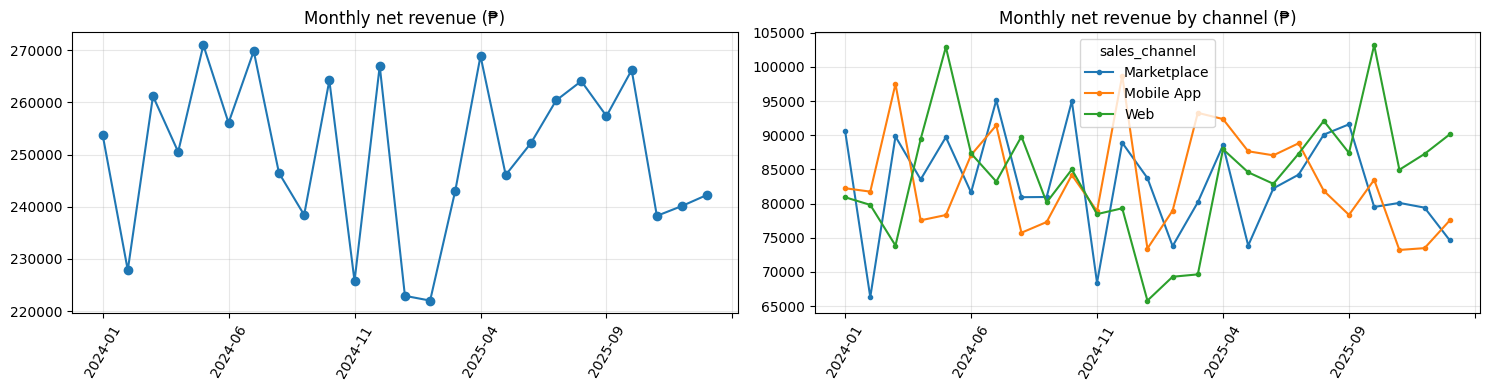

,sum,count,months,avg_per_month
order_datetime,,,,
2024,"3,032,011.00",16461,12,"252,668.00"
2025,"2,981,539.00",16243,12,"248,462.00"
2026,"242,289.00",1311,1,"242,289.00"


Monthly revenue: mean ₱250,234, min ₱222,027, max ₱270,952, variation (std/mean) 6.1%
First month: 2024-01 ₱253,833 | Last month: 2026-01 ₱242,289
Best 3 months : {'2024-05': 270952.0, '2024-07': 269802.0, '2025-04': 268861.0}
Worst 3 months: {'2025-02': 222027.0, '2025-01': 222940.0, '2024-11': 225764.0}

Channel totals:


,sum,count,share_pct
sales_channel,,,
Marketplace,"2,072,857.21",11272,33.13
Mobile App,"2,080,254.26",11395,33.25
Web,"2,102,727.74",11348,33.61


In [23]:
monthly = rev.groupby("order_month")["net_revenue"].sum()
by_channel = rev.pivot_table(index="order_month", columns="sales_channel", values="net_revenue", aggfunc="sum")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
monthly.plot(ax=ax[0], marker="o", title="Monthly net revenue (₱)"); ax[0].set_xlabel("")
by_channel.plot(ax=ax[1], marker=".", title="Monthly net revenue by channel (₱)"); ax[1].set_xlabel("")
for a in ax: a.tick_params(axis="x", rotation=60); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

yearly = rev.groupby(rev["order_datetime"].dt.year)["net_revenue"].agg(["sum", "count"]); yearly["months"] = rev.groupby(rev["order_datetime"].dt.year)["order_month"].nunique()
yearly["avg_per_month"] = yearly["sum"] / yearly["months"]; display(yearly.round(0))
print(f"Monthly revenue: mean ₱{monthly.mean():,.0f}, min ₱{monthly.min():,.0f}, max ₱{monthly.max():,.0f}, variation (std/mean) {monthly.std() / monthly.mean() * 100:.1f}%")
print("First month:", monthly.index[0], f"₱{monthly.iloc[0]:,.0f}", "| Last month:", monthly.index[-1], f"₱{monthly.iloc[-1]:,.0f}")
print("Best 3 months :", monthly.nlargest(3).round(0).to_dict())
print("Worst 3 months:", monthly.nsmallest(3).round(0).to_dict())
print("\nChannel totals:"); display(rev.groupby("sales_channel")["net_revenue"].agg(["sum", "count"]).assign(share_pct=lambda d: d["sum"] / d["sum"].sum() * 100).round(2))

**Finding:** Revenue is flat, not growing. The store earns about ₱250,000 net revenue a month and the monthly figure stays inside a narrow band (₱222k to ₱271k, roughly ±6%). The average month in 2024 (₱252.7k) was slightly higher than in 2025 (₱248.5k), a drop of about 1.7%, so there is no growth trend and no strong seasonal peak. The best month was May 2024 (₱271k); the weakest were January and February 2025 (₱222k–223k). The three channels are almost equal: Web 33.6%, Mobile App 33.3%, Marketplace 33.1%. **Plain meaning:** no channel is carrying the business, and growth would have to come from somewhere other than shifting between channels.

### Q2. Which product categories perform best (revenue, units, share, margin)?

,revenue,units,orders,cost,share_pct,gross_margin_pct
category,,,,,,
Toys,"878,849.91",9562,3943,"612,375.29",14.05,30.32
Electronics,"851,152.68",10517,4276,"588,061.96",13.61,30.91
Fashion,"806,408.30",8925,3695,"573,149.90",12.89,28.93
Beauty,"796,544.71",9604,3905,"564,685.20",12.73,29.11
Home & Kitchen,"794,845.82",8970,3715,"571,953.25",12.71,28.04
Books,"733,197.33",9722,4036,"528,088.62",11.72,27.97
Groceries,"721,953.99",8125,3400,"502,964.17",11.54,30.33
Sports,"672,886.47",7264,3112,"478,926.06",10.76,28.83


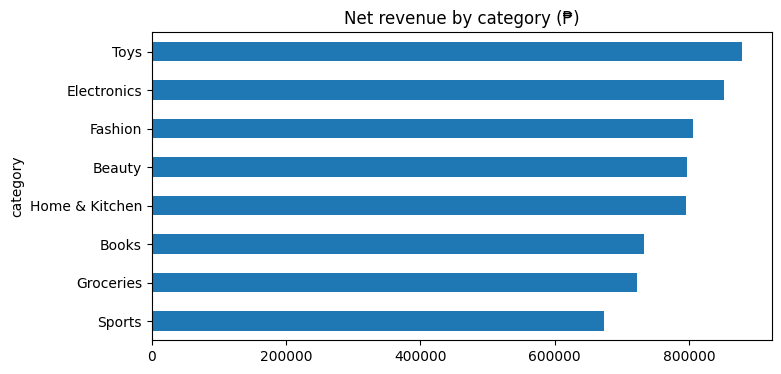

In [24]:
cat = (rev.groupby("category")
          .agg(revenue=("net_revenue", "sum"), units=("quantity", "sum"), orders=("order_id", "nunique"),
               cost=("cost_amount", "sum"))
          .assign(share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100,
                  gross_margin_pct=lambda d: (d["revenue"] - d["cost"]) / d["revenue"] * 100)
          .sort_values("revenue", ascending=False))
display(cat.round(2))
cat["revenue"].sort_values().plot.barh(title="Net revenue by category (₱)", figsize=(8, 4)); plt.show()

**Finding:** Toys is the top category (₱879k, 14.1% of revenue), followed by Electronics (₱851k, 13.6%) and Fashion (₱806k, 12.9%). Sports is the smallest (₱673k, 10.8%). The gap from first to last is only about 3 percentage points, so the categories are fairly balanced. Electronics sells the most units (10,517) and has the best gross margin (30.9%); Books has the lowest margin (28.0%). **Why cleaning mattered:** before standardizing, Electronics was spread across 4 labels (`Electronics`, `electronics`, `Elec`, ...) and would have looked much smaller than it really is.

### Q3. Who are the top 10 products by revenue and by quantity?

In [25]:
prod = (rev.groupby(["product_id", "product_name", "category"])
           .agg(revenue=("net_revenue", "sum"), units=("quantity", "sum")).reset_index())
print("TOP 10 BY REVENUE"); display(prod.nlargest(10, "revenue").round(2).reset_index(drop=True))
print("TOP 10 BY QUANTITY"); display(prod.nlargest(10, "units").round(2).reset_index(drop=True))
overlap = set(prod.nlargest(10, "revenue")["product_id"]) & set(prod.nlargest(10, "units")["product_id"])
print(f"Products in both top-10 lists: {len(overlap)}")
top10_share = prod.nlargest(10, "revenue")["revenue"].sum() / prod["revenue"].sum() * 100
print(f"Top 10 products = {top10_share:.1f}% of revenue (out of {len(prod)} products sold)")

TOP 10 BY REVENUE


,product_id,product_name,category,revenue,units
0,PROD00608,KidJoy Toys 607,Toys,"35,389.43",89
1,PROD00137,FreshCart Fashion 562,Fashion,"29,108.07",81
2,PROD00061,UrbanWear Groceries 328,Groceries,"25,697.19",132
3,PROD00651,FitPro Home 691,Home & Kitchen,"23,817.84",85
4,PROD00720,BookNest Toys 264,Toys,"23,722.04",97
5,PROD00412,GlowCo Fashion 931,Fashion,"22,512.82",116
6,PROD00173,HomeEase Sports 288,Sports,"22,472.37",106
7,PROD00317,KidJoy Beauty 543,Beauty,"22,379.90",152
8,PROD00452,HomeEase Groceries 174,Groceries,"21,906.50",126
9,PROD00200,KidJoy Electronics 910,Electronics,"21,613.28",66


TOP 10 BY QUANTITY


,product_id,product_name,category,revenue,units
0,PROD00317,KidJoy Beauty 543,Beauty,"22,379.90",152
1,PROD00381,KidJoy Books 119,Books,"5,161.22",150
2,PROD00537,NovaTech Fashon 786,Fashion,"18,205.42",133
3,PROD00016,GlowCo Beauty 695,Beauty,"6,460.49",132
4,PROD00061,UrbanWear Groceries 328,Groceries,"25,697.19",132
5,PROD00207,KidJoy Electronics 356,Electronics,"9,272.36",131
6,PROD00216,KidJoy Electronics 445,Electronics,"5,404.23",130
7,PROD00528,Acme Beauty 106,Beauty,"9,592.67",130
8,PROD00104,HomeEase Home 231,Home & Kitchen,"12,045.62",128
9,PROD00275,NovaTech Fashion 102,Fashion,"18,725.18",128


Products in both top-10 lists: 2
Top 10 products = 4.0% of revenue (out of 800 products sold)


**Finding:** There is no "hero product". The #1 product by revenue (KidJoy Toys 607, ₱35.4k from 89 units) is a tiny slice of the business, and the top 10 products together make only 4.0% of revenue out of 800 products sold. Only 2 products appear in both the top-10 by revenue and the top-10 by quantity, because they are different things: KidJoy Books 119 sold 150 units but made only ₱5.2k (a cheap item), while KidJoy Toys 607 made the most money with fewer units. **Plain meaning:** sales are spread across the whole catalogue, so ranking by revenue and ranking by units answer different business questions.

### Q4. Customer segmentation by total spend — and how do regions compare?

In [26]:
cust = (rev[~rev["orphan_customer"]].groupby("customer_id")
           .agg(total_spend=("net_revenue", "sum"), orders=("order_id", "nunique")).reset_index())
cust["segment"] = pd.qcut(cust["total_spend"], q=[0, .5, .8, .95, 1.0], labels=["Low (bottom 50%)", "Mid (50-80%)", "High (80-95%)", "VIP (top 5%)"])
seg = cust.groupby("segment", observed=True).agg(customers=("customer_id", "count"), total_spend=("total_spend", "sum"),
                                                  avg_spend=("total_spend", "mean"), avg_orders=("orders", "mean"))
seg["share_of_revenue_pct"] = seg["total_spend"] / seg["total_spend"].sum() * 100
display(seg.round(2))

region = (rev[~rev["orphan_customer"]].groupby("region_name")
             .agg(revenue=("net_revenue", "sum"), customers=("customer_id", "nunique"), orders=("order_id", "nunique")))
region["revenue_per_customer"] = region["revenue"] / region["customers"]
region["avg_order_value"] = region["revenue"] / region["orders"]
display(region.sort_values("revenue", ascending=False).round(2))

print("Average spend by loyalty tier:")
display(rev[~rev["orphan_customer"]].groupby("loyalty_tier")["net_revenue"].sum().div(
        rev[~rev["orphan_customer"]].groupby("loyalty_tier")["customer_id"].nunique()).round(2).rename("revenue_per_customer").to_frame())

,customers,total_spend,avg_spend,avg_orders,share_of_revenue_pct
segment,,,,,
Low (bottom 50%),2346,"1,519,810.91",647.83,1.97,24.37
Mid (50-80%),1407,"2,181,807.18","1,550.68",3.30,34.98
High (80-95%),704,"1,686,358.41","2,395.40",4.36,27.04
VIP (top 5%),235,"849,157.23","3,613.44",5.80,13.61


,revenue,customers,orders,revenue_per_customer,avg_order_value
region_name,,,,,
Central Luzon,"1,074,390.11",797,2371,"1,348.04",453.14
Central Visayas,"1,057,215.41",797,2339,"1,326.49",451.99
Metro Manila,"1,049,467.12",799,2284,"1,313.48",459.49
Northern Mindanao,"1,026,960.67",751,2216,"1,367.46",463.43
Caraga,"1,025,730.42",763,2248,"1,344.34",456.29
CALABARZON,"1,003,370.00",785,2238,"1,278.18",448.33


Average spend by loyalty tier:


,revenue_per_customer
loyalty_tier,
Bronze,"1,352.54"
Gold,"1,334.90"
Platinum,"1,251.37"
Silver,"1,313.64"
Unknown,"1,294.98"


**Finding:** Spending is spread out, not concentrated. The top 5% of customers (235 VIPs) bring in 13.6% of revenue, and the top 20% (939 customers) bring about 41%, much less than the "80/20 rule". The bottom half of customers (2,346 people) still contributes 24%. Higher spenders mostly just **order more often** (about 5.8 orders for VIPs vs 2.0 for the lowest group). Regions are close: Central Luzon is highest (₱1.07M) and CALABARZON lowest (₱1.00M), a gap of about 7%; per customer, Northern Mindanao is highest (₱1,367). **Loyalty tier does not predict spending** (Bronze ₱1,353 per customer vs Platinum ₱1,251), which suggests the tiers are not linked to actual purchases. *(Orders from the orphan customer `CUST999999` are excluded here because their region/tier is unknown.)*

### Q5. How is delivery performance by courier (lead time, late deliveries, lost shipments)?

In [27]:
print(shipments_clean["lead_days"].describe().round(2).to_string())
LATE_DAYS = 5   # business-rule ASSUMPTION: lead times run 1-7 days, so "late" = more than 5 days after ship date
print(f"\nDefinition: late delivery = lead time > {LATE_DAYS} days (assumed rule; change LATE_DAYS to test others)")

d = shipments_clean[(shipments_clean["shipment_status"] == "Delivered") & shipments_clean["lead_days"].notna()]   # need a delivered_date to measure lead time
deliv = d.groupby("courier").agg(delivered=("shipment_id", "count"), avg_lead_days=("lead_days", "mean"),
                                  late_pct=("lead_days", lambda x: (x > LATE_DAYS).mean() * 100))
status = pd.crosstab(shipments_clean["courier"], shipments_clean["shipment_status"], normalize="index") * 100
perf = deliv.join(status[["Lost", "Returned to Sender", "In Transit"]].add_suffix("_%"))
display(perf.sort_values("avg_lead_days").round(2))
max_ship = shipments_clean["ship_date"].max()
stale = shipments_clean[(shipments_clean["shipment_status"] == "In Transit") & (shipments_clean["ship_date"] < max_ship - pd.Timedelta(days=30))]
print(f"\n'In Transit' for more than 30 days after ship date: {len(stale):,} shipments ({len(stale) / (shipments_clean['shipment_status'] == 'In Transit').sum() * 100:.1f}% of all In Transit) -> status probably never updated")
print("Overall status mix (%):"); print((shipments_clean["shipment_status"].value_counts(normalize=True) * 100).round(2).to_string())

count   14,271.00
mean         4.00
std          1.99
min          1.00
25%          2.00
50%          4.00
75%          6.00
max          7.00

Definition: late delivery = lead time > 5 days (assumed rule; change LATE_DAYS to test others)


,delivered,avg_lead_days,late_pct,Lost_%,Returned to Sender_%,In Transit_%
courier,,,,,,
NinjaVan,2233,3.97,28.12,0.84,3.12,17.59
LBC,2262,3.98,27.90,1.06,2.79,17.60
2GO,2169,4.01,29.28,1.05,3.08,18.43
J&T,2221,4.02,27.51,1.25,3.58,18.57
GrabExpress,2237,4.03,29.19,1.16,2.92,17.60



'In Transit' for more than 30 days after ship date: 2,575 shipments (95.6% of all In Transit) -> status probably never updated
Overall status mix (%):
shipment_status
Delivered            77.87
In Transit           17.96
Returned to Sender    3.10
Lost                  1.07


**Finding:** All five couriers perform almost the same. Average delivery time is about 4.0 days for every courier (3.97 to 4.03), and 28–29% of delivered parcels take more than 5 days (J&T and LBC slightly better at ~27.5–27.9%, 2GO and GrabExpress slightly worse at ~29%). Lost parcels are 1.07% overall (J&T highest at 1.25%, NinjaVan lowest at 0.84%) and 3.1% are Returned to Sender (J&T highest at 3.6%). These differences are small, so I would not call any courier clearly better on this data. **Data warning:** 18% of shipments are still "In Transit", and 95.6% of them were shipped more than 30 days before the end of the data, so the status was probably never updated. 3,707 shipments also have a status that contradicts the delivered date. Lead time was therefore measured only on shipments marked Delivered *with* a delivered date.

### Q6. Which categories have the highest return rate, and why do customers return?

In [28]:
ret_orders = set(returns_clean["order_id"])
lines = items[items["valid_line"]].copy()
lines["returned"] = lines["order_id"].isin(ret_orders)
rr = lines.groupby("category").agg(lines=("order_item_id", "count"), returned_lines=("returned", "sum"))
rr["return_rate_pct"] = rr["returned_lines"] / rr["lines"] * 100
display(rr.sort_values("return_rate_pct", ascending=False).round(2))

print(f"Return rate (orders): {len(ret_orders) / orders_clean['order_id'].nunique() * 100:.2f}% of orders have a return record")
print("\nReasons:"); print(returns_clean["reason"].value_counts().to_string())
print("\nRefund status:"); print(returns_clean["refunded_flag"].value_counts().to_string())
by_courier = (shipments_clean.assign(returned=shipments_clean["order_id"].isin(ret_orders))
              .groupby("courier")["returned"].mean().mul(100).round(2).rename("return_rate_%"))
print("\nReturn rate by courier (% of orders):"); print(by_courier.to_string())
print("\nOrders with a return record by order_status:"); print(orders_clean.assign(has_return=orders_clean["order_id"].isin(ret_orders)).groupby("order_status")["has_return"].agg(["sum", "mean"]).round(3).to_string())

,lines,returned_lines,return_rate_pct
category,,,
Home & Kitchen,4522,404,8.93
Fashion,4519,382,8.45
Beauty,4828,393,8.14
Sports,3777,305,8.08
Books,5013,386,7.70
Toys,4864,370,7.61
Electronics,5373,406,7.56
Groceries,4106,310,7.55


Return rate (orders): 8.00% of orders have a return record

Reasons:
reason
Changed mind     182
Defective        178
Missing parts    175
Size issue       174
Late delivery    169
Wrong item       162
Damaged item     160

Refund status:
refunded_flag
Yes        653
No         301
Partial    136
Unknown    110

Return rate by courier (% of orders):
courier
2GO           7.01
GrabExpress   8.44
J&T           8.61
LBC           7.11
NinjaVan      8.81

Orders with a return record by order_status:
              sum  mean
order_status           
Cancelled      85  0.07
Completed     814  0.08
Pending       116  0.08
Returned       40  0.07
Shipped       145  0.08


**Finding:** 8.0% of orders (1,200 of 15,000) have a return record. Home & Kitchen has the highest return rate (8.9% of order lines) and Fashion is next (8.5%); Groceries and Electronics are lowest (about 7.6%). The spread is only about 1.4 points, so category is not a strong driver. Return reasons are nearly evenly split (Changed mind 182 ... Damaged item 160), so there is no single dominant cause to fix. NinjaVan (8.8%) and J&T (8.6%) have a somewhat higher share of returned orders than 2GO (7.0%) and LBC (7.1%). **Data warning:** the returns data is unreliable: 481 of 1,200 refund records (40%) have a refund flag that contradicts the amount, 201 returns are attached to Cancelled/Pending orders, and only 40 of the 578 orders with status *Returned* have a return record. Return figures should be treated as indicative only.

### Q7. Can we trust `payments.amount_paid`? (data-integrity question)

Payments that match the computed total: 0.1%
Payments that do NOT match            : 99.9%
Mean absolute difference              : ₱1,099.20
Total recorded payments               : ₱21,316,752.45
Total computed order value (same orders): ₱7,567,641.41

Mismatch rate for orders WITHOUT zero-qty/orphan lines: 99.9%


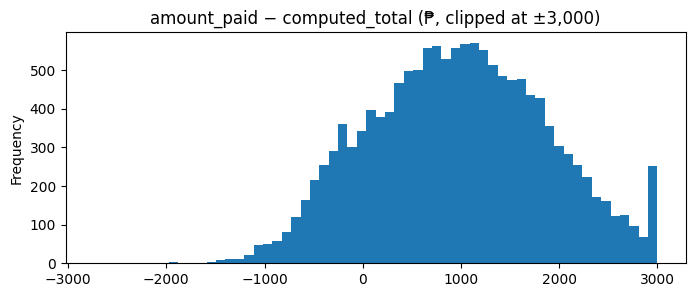

In [29]:
known = order_check["amount_paid"].notna()
m = order_check[known]
print(f"Payments that match the computed total: {(~m['payment_mismatch']).mean() * 100:.1f}%")
print(f"Payments that do NOT match            : {m['payment_mismatch'].mean() * 100:.1f}%")
print(f"Mean absolute difference              : ₱{m['diff'].abs().mean():,.2f}")
print(f"Total recorded payments               : ₱{m['amount_paid'].sum():,.2f}")
print(f"Total computed order value (same orders): ₱{m['computed_total'].sum():,.2f}")
print()
print("Mismatch rate for orders WITHOUT zero-qty/orphan lines:",
      f"{m[(m['has_zero_qty'] == False) & (m['has_orphan_product'] == False)]['payment_mismatch'].mean() * 100:.1f}%")
m["diff"].clip(-3000, 3000).plot.hist(bins=60, title="amount_paid − computed_total (₱, clipped at ±3,000)", figsize=(8, 3)); plt.show()

**Finding:** `amount_paid` cannot be trusted as revenue. Only 8 of 14,122 recorded payments (0.1%) match the computed order total (item totals after discount + shipping fee). The mismatch happens for every payment status, even orders with clean lines, and recorded payments add up to ₱21.3M against ₱7.6M computed for the same orders (about 2.8 times higher). Even *Failed* payments carry an amount. **Plain meaning:** this matches the README note that payments are intentionally inconsistent, so all revenue in this notebook is computed from `order_items` (quantity × price × (1 − discount)) and not taken from the payments table.

## 6. Cleaning decisions log

Each row answers the trainer's question: **what changed, why, and how I verified it.** Counts are computed from the code above, not typed by hand.

In [30]:
L = log_counts
decisions = pd.DataFrame([
 ("1", "Remove exact duplicate rows (customers, orders, order_items)",
  f"customers −{L['cust_dups']}, orders −{L['orders_dups']}, order_items −{L['items_dups']}",
  "README says order_id duplicates are intentional. Counting the same order / item twice would inflate revenue. I only dropped rows identical in EVERY column, so no real record is lost.",
  "After drop_duplicates, assert that customer_id, order_id and order_item_id are unique (this also proves no 'near-duplicates' were hiding)."),
 ("2", "Convert currency strings to numbers (products, order_items, payments)",
  f"Removed ₱ and commas: {L['prod_currency_fixed']} product cells, {L['item_currency_fixed']} item prices, {L['pay_currency_fixed']} payment amounts",
  "'₱1,234.56' is text; it cannot be summed or averaged, and the column is dtype object.",
  "Non-null count before == non-null count after (parsing created no new NaN); dtypes are float64."),
 ("3", "Normalize customers.gender",
  "M/F/Male/Female/female/Unknown/blank → Male / Female / Unknown",
  "Same person-type was spelled 6+ ways, so a groupby would split one group into several. Blank and 'Unknown' both mean 'not known'.",
  "assert only {Male, Female, Unknown} remain; value_counts total equals row count."),
 ("4", "Standardize products.category",
  f"{L['cat_before']} labels → {L['cat_after']} categories (Fashon→Fashion, Elec→Electronics, Grocery→Groceries, ...)",
  "Typos/casing split categories, which would give wrong category revenue rankings.",
  "Explicit mapping dictionary + assert that every raw label is mapped (code fails if a new variant appears)."),
 ("5", "Parse mixed date fields (signup, order_datetime, payment, ship, delivered, return, launch)",
  "3 text formats → one datetime64 type",
  "Text dates sort alphabetically and cannot be used for monthly trends or lead times. Formats are tried explicitly (README: MM/DD/YYYY, not DD/MM) instead of letting pandas guess.",
  "Count of valid dates before == after for each column (no date lost, none invented); min/max range printed."),
 ("6", "Flag (not delete) invalid ages",
  f"{L['age_invalid']} negative ages → NaN + age_invalid flag",
  "An age below 0 is impossible, so the value is unreliable, but the customer and their orders are still real.",
  "assert no negative age remains; flag count equals number of changed rows."),
 ("7", "Flag zero-quantity items",
  f"{L['zero_qty']} rows kept with zero_qty = True, excluded from revenue via valid_line",
  "Quantity 0 has no sales value; deleting rows would change order structure, flagging keeps the audit trail.",
  "Zero-qty lines have net_revenue 0 and are excluded from every revenue calculation (valid_line)."),
 ("8", "Flag orphan keys (customer_id, product_id)",
  f"{L['orphan_customer_orders']} orders with unknown customer, {L['orphan_product']} item rows with unknown product",
  "Foreign keys that don't exist (CUST999999, PROD00000) would be silently lost by an inner join. Left joins + flag keep them visible; category set to 'Unknown (orphan product)'.",
  "validate='many_to_one' on every merge + assert row count of analysis table == order_items_clean."),
 ("9", "Backfill missing unit_price_at_purchase from products.unit_price",
  f"{L['price_backfilled']} prices backfilled, {L['price_unavailable']} still unavailable (orphan product)",
  "README allows it. Without a price those lines would have no revenue at all. Source is recorded in price_source so it can be audited or excluded.",
  "price_source value_counts; remaining nulls are only lines whose product does not exist."),
 ("10", "Flag inconsistent refund records",
  f"{L['refund_inconsistent']} returns rows flagged (e.g. 'Yes' with no amount, 'No' with an amount)",
  "A refund flag and amount that disagree cannot both be right; picking one would be a guess, so they are flagged for the business to confirm. Blank flag → 'Unknown'.",
  "Cross-tab of refunded_flag vs amount shown; each flagged row carries a refund_issue text."),
 ("11", "Keep missing discount/shipping fee as NaN, add *_filled (0) only for maths",
  f"discount_pct missing: {L['disc_missing']}, shipping_fee missing: {L['ship_missing']}",
  "Original values are not overwritten, so the assumption (no discount / no fee) is visible and reversible.",
  "*_missing flag counts equal original null counts."),
 ("12", "Flag shipment status vs delivered_date conflicts",
  f"{L['ship_conflict']} rows (e.g. 'In Transit' but delivered date filled)",
  "Delivery performance results depend on these fields; contradictory rows are flagged rather than guessed.",
  "Crosstab of shipment_status vs has_delivered_date printed."),
], columns=["#", "Decision", "What changed", "Why", "How verified"])
pd.set_option("display.max_colwidth", None)
decisions

,#,Decision,What changed,Why,How verified
0,1,"Remove exact duplicate rows (customers, orders, order_items)","customers −50, orders −75, order_items −262","README says order_id duplicates are intentional. Counting the same order / item twice would inflate revenue. I only dropped rows identical in EVERY column, so no real record is lost.","After drop_duplicates, assert that customer_id, order_id and order_item_id are unique (this also proves no 'near-duplicates' were hiding)."
1,2,"Convert currency strings to numbers (products, order_items, payments)","Removed ₱ and commas: 68 product cells, 3017 item prices, 556 payment amounts","'₱1,234.56' is text; it cannot be summed or averaged, and the column is dtype object.",Non-null count before == non-null count after (parsing created no new NaN); dtypes are float64.
2,3,Normalize customers.gender,M/F/Male/Female/female/Unknown/blank → Male / Female / Unknown,"Same person-type was spelled 6+ ways, so a groupby would split one group into several. Blank and 'Unknown' both mean 'not known'.","assert only {Male, Female, Unknown} remain; value_counts total equals row count."
3,4,Standardize products.category,"18 labels → 8 categories (Fashon→Fashion, Elec→Electronics, Grocery→Groceries, ...)","Typos/casing split categories, which would give wrong category revenue rankings.",Explicit mapping dictionary + assert that every raw label is mapped (code fails if a new variant appears).
4,5,"Parse mixed date fields (signup, order_datetime, payment, ship, delivered, return, launch)",3 text formats → one datetime64 type,"Text dates sort alphabetically and cannot be used for monthly trends or lead times. Formats are tried explicitly (README: MM/DD/YYYY, not DD/MM) instead of letting pandas guess.","Count of valid dates before == after for each column (no date lost, none invented); min/max range printed."
5,6,Flag (not delete) invalid ages,48 negative ages → NaN + age_invalid flag,"An age below 0 is impossible, so the value is unreliable, but the customer and their orders are still real.",assert no negative age remains; flag count equals number of changed rows.
6,7,Flag zero-quantity items,"372 rows kept with zero_qty = True, excluded from revenue via valid_line","Quantity 0 has no sales value; deleting rows would change order structure, flagging keeps the audit trail.",Zero-qty lines have net_revenue 0 and are excluded from every revenue calculation (valid_line).
7,8,"Flag orphan keys (customer_id, product_id)","43 orders with unknown customer, 129 item rows with unknown product","Foreign keys that don't exist (CUST999999, PROD00000) would be silently lost by an inner join. Left joins + flag keep them visible; category set to 'Unknown (orphan product)'.",validate='many_to_one' on every merge + assert row count of analysis table == order_items_clean.
8,9,Backfill missing unit_price_at_purchase from products.unit_price,"2227 prices backfilled, 9 still unavailable (orphan product)",README allows it. Without a price those lines would have no revenue at all. Source is recorded in price_source so it can be audited or excluded.,price_source value_counts; remaining nulls are only lines whose product does not exist.
9,10,Flag inconsistent refund records,"481 returns rows flagged (e.g. 'Yes' with no amount, 'No' with an amount)","A refund flag and amount that disagree cannot both be right; picking one would be a guess, so they are flagged for the business to confirm. Blank flag → 'Unknown'.",Cross-tab of refunded_flag vs amount shown; each flagged row carries a refund_issue text.


## 7. Export cleaned outputs

In [31]:
outputs = {"customers_clean": customers_clean, "products_clean": products_clean, "orders_clean": orders_clean,
           "order_items_clean": order_items_clean, "payments_clean": payments_clean,
           "shipments_clean": shipments_clean, "returns_clean": returns_clean,
           "item_level_analysis": items, "order_payment_check": order_check,
           "data_quality_flags": flag_summary, "cleaning_decisions_log": decisions}
for name, df in outputs.items():
    df.to_csv(f"{OUT_DIR}/{name}.csv", index=False)
    print(f"saved {OUT_DIR}/{name}.csv  {df.shape}")

# final verification: re-read the saved files and check the key rules still hold
chk = {k: pd.read_csv(f"{OUT_DIR}/{k}.csv") for k in ["customers_clean", "orders_clean", "order_items_clean", "products_clean"]}
assert chk["customers_clean"]["customer_id"].is_unique and chk["orders_clean"]["order_id"].is_unique
assert chk["order_items_clean"]["order_item_id"].is_unique and chk["products_clean"]["product_id"].is_unique
assert pd.api.types.is_numeric_dtype(chk["products_clean"]["unit_price"])
assert chk["products_clean"]["category"].nunique() == 8
print("\n[OK] Saved files re-loaded and verified.")

saved cleaned_outputs/customers_clean.csv  (5000, 16)
saved cleaned_outputs/products_clean.csv  (800, 11)


saved cleaned_outputs/orders_clean.csv  (15000, 13)
saved cleaned_outputs/order_items_clean.csv  (37501, 9)
saved cleaned_outputs/payments_clean.csv  (15000, 7)


saved cleaned_outputs/shipments_clean.csv  (15000, 10)
saved cleaned_outputs/returns_clean.csv  (1200, 11)


saved cleaned_outputs/item_level_analysis.csv  (37501, 29)
saved cleaned_outputs/order_payment_check.csv  (15000, 11)
saved cleaned_outputs/data_quality_flags.csv  (10, 3)
saved cleaned_outputs/cleaning_decisions_log.csv  (12, 5)



[OK] Saved files re-loaded and verified.


## 8. Summary of findings

1. **Data quality:** the data needed real cleaning: 387 exact duplicates removed (50 customers, 75 orders, 262 order items), 18 category labels collapsed to 8, 3,600+ currency strings converted, 3 date formats unified, and 10 types of bad records flagged (orphan IDs, zero quantity, negative age, bad refund records, shipment conflicts, ...).
2. **Business:** revenue is flat at about ₱250k/month (₱6.26M net over 25 months); the three channels, eight categories, six regions and five couriers are all close to each other. There is no single star channel, product or courier.
3. **Customers:** spending is not concentrated; loyalty tier does not relate to spending.
4. **Do not rely on:** `payments.amount_paid`, the refund flags, shipment statuses, or `order_status = Returned` for reporting without confirming with the business.
5. **Assumptions to state when presenting:** MM/DD/YYYY for slash dates (per README); cancelled orders excluded from revenue; missing discount/shipping fee treated as 0 for maths only; "late" = more than 5 days; missing item prices backfilled from the product master.